In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import os

print(os.getcwd())
print(os.listdir())

/workspaces/Proyecto_Programacion_2/cuadernos
['exploracion_Sofia.ipynb']


In [4]:
import os

print(os.listdir("../Datos"))

['fifa21_muestra_2000.csv']


In [5]:
df = pd.read_csv("../Datos/fifa21_muestra_2000.csv")

In [6]:
df.head()
df.shape

(2000, 77)

In [7]:
# Revisar la cantidad de datos faltantes por columna
print(df.isnull().sum()[df.isnull().sum() > 0])

Loan Date End    1890
dtype: int64


In [8]:
# Calcular el porcentaje de datos faltantes

porcentaje = (df["Loan Date End"].isnull().sum() / len(df)) * 100
print("Porcentaje de datos faltantes:", porcentaje, "%")

Porcentaje de datos faltantes: 94.5 %


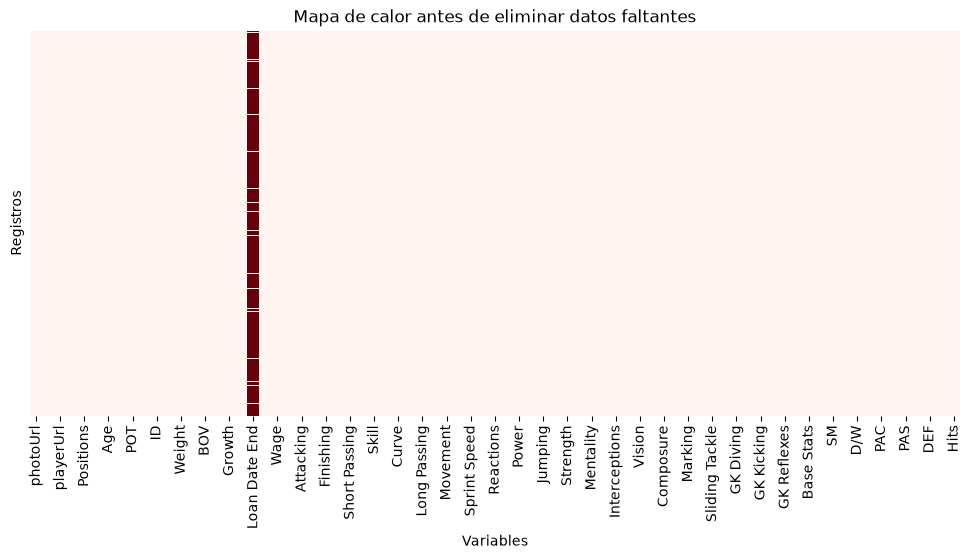

In [9]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="Reds")
plt.title("Mapa de calor antes de eliminar datos faltantes")
plt.xlabel("Variables")
plt.ylabel("Registros")

plt.show()

In [10]:
# Eliminar la columna Loan Date End

df = df.drop(columns=["Loan Date End"])

In [11]:
print("Dimensiones después de la limpieza:", df.shape)

print("Total de datos faltantes:", df.isnull().sum().sum())

Dimensiones después de la limpieza: (2000, 76)
Total de datos faltantes: 0


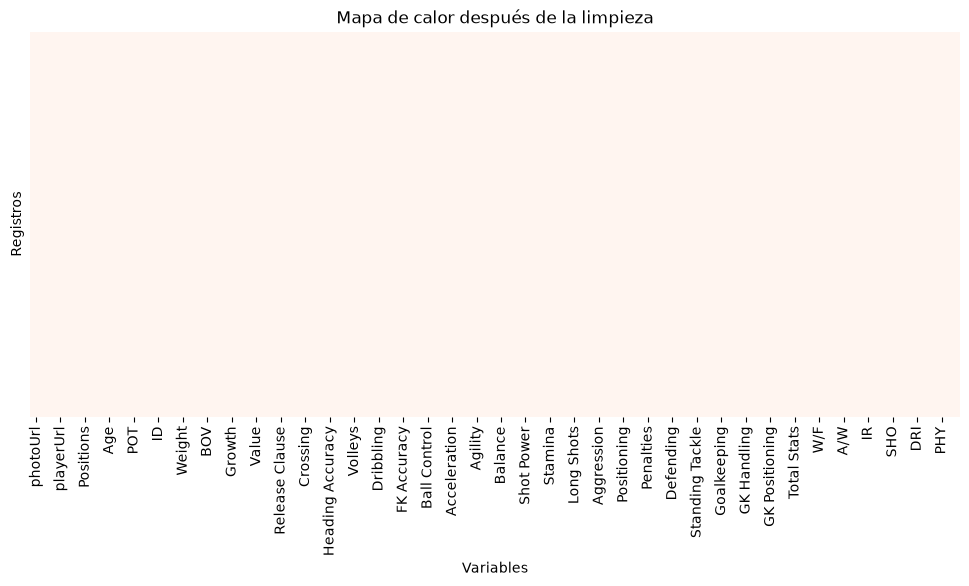

In [12]:
plt.figure(figsize=(12, 5))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap = "Reds")

plt.title("Mapa de calor después de la limpieza")
plt.xlabel("Variables")
plt.ylabel("Registros")

plt.show()

In [13]:
# Identificar registros duplicados

print("Cantidad de registros duplicados:", df.duplicated().sum())

Cantidad de registros duplicados: 0


In [14]:
df[df.duplicated()]

,photoUrl,LongName,playerUrl,Nationality,Positions,Name,Age,↓OVA,POT,Team & Contract,...,A/W,D/W,IR,PAC,SHO,PAS,DRI,DEF,PHY,Hits


In [15]:
# Actualizar las columnas de texto

columnas_texto = df.select_dtypes(include="object").columns

/tmp/ipykernel_102319/4074717302.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_texto = df.select_dtypes(include="object").columns


In [16]:
# Revisar algunos valores de Team & Contract

print(df["Team & Contract"].head(10).tolist())

['\n\n\n\nCerezo Osaka\n2013 ~ 2021\n\n', '\n\n\n\nReal Sporting de Gijón\n2017 ~ 2021\n\n', '\n\n\n\nGoiás\n2019 ~ 2023\n\n', '\n\n\n\nGuadalajara\n2020 ~ 2023\n\n', '\n\n\n\nSagan Tosu\n2019 ~ 2023\n\n', '\n\n\n\n1. FSV Mainz 05\n2015 ~ 2021\n\n', '\n\n\n\nCrawley Town\n2020 ~ 2021\n\n', '\n\n\n\nBeerschot AC\n2018 ~ 2021\n\n', '\n\n\n\nCeltic\nJun 30, 2021 On Loan\n\n', '\n\n\n\nRoyal Excel Mouscron\nJun 30, 2021 On Loan\n\n']


In [17]:
# Comparar los valores originales con los corregidos

print(df["Team & Contract"].str.strip().head(10).tolist())

['Cerezo Osaka\n2013 ~ 2021', 'Real Sporting de Gijón\n2017 ~ 2021', 'Goiás\n2019 ~ 2023', 'Guadalajara\n2020 ~ 2023', 'Sagan Tosu\n2019 ~ 2023', '1. FSV Mainz 05\n2015 ~ 2021', 'Crawley Town\n2020 ~ 2021', 'Beerschot AC\n2018 ~ 2021', 'Celtic\nJun 30, 2021 On Loan', 'Royal Excel Mouscron\nJun 30, 2021 On Loan']


In [18]:
# Corregir espacios y saltos de línea en Team & Contract

df["Team & Contract"] = df["Team & Contract"].str.replace("\n", " ", regex=False).str.strip()

In [19]:
print(df["Team & Contract"].head(10).tolist())

['Cerezo Osaka 2013 ~ 2021', 'Real Sporting de Gijón 2017 ~ 2021', 'Goiás 2019 ~ 2023', 'Guadalajara 2020 ~ 2023', 'Sagan Tosu 2019 ~ 2023', '1. FSV Mainz 05 2015 ~ 2021', 'Crawley Town 2020 ~ 2021', 'Beerschot AC 2018 ~ 2021', 'Celtic Jun 30, 2021 On Loan', 'Royal Excel Mouscron Jun 30, 2021 On Loan']


In [20]:
# Buscar espacios innecesarios en las columnas de texto
for columna in columnas_texto:
    cantidad = (df[columna] != df[columna].str.strip()).sum()

    if cantidad > 0:
        print(f"{columna}: {cantidad} valores con espacios innecesarios")

Hits: 2000 valores con espacios innecesarios


In [21]:
# Revisar los primeros valores de Hits

print(df["Hits"].head(10).tolist())

['\n3', '\n11', '\n2', '\n3', '\n3', '\n11', '\n2', '\n1', '\n28', '\n3']


In [22]:
# Comparar los valores sin espacios

print(df["Hits"].str.strip().head(10).tolist())

['3', '11', '2', '3', '3', '11', '2', '1', '28', '3']


In [23]:
# Limpiar espacios y saltos de línea en las columnas de texto

for columna in columnas_texto:
    df[columna] = df[columna].str.replace("\n", " ", regex=False).str.strip()

In [24]:
# Comprobar si quedan espacios innecesarios

for columna in columnas_texto:
    cantidad = (df[columna] != df[columna].str.strip()).sum()

    if cantidad > 0:
        print(columna, cantidad)

In [25]:
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 0


In [26]:
# Revisar valores únicos de las variables categóricas

for columna in ["Nationality", "Positions", "foot", "BP"]:
    print("\n", columna)
    print(df[columna].value_counts())


 Nationality
Nationality
England             163
Germany             141
France              111
Spain               108
Brazil               95
                   ... 
Sierra Leone          1
Zambia                1
Papua New Guinea      1
Puerto Rico           1
Libya                 1
Name: count, Length: 124, dtype: int64

 Positions
Positions
CB           257
GK           224
ST           187
CDM CM        88
CM            79
            ... 
RB RM RW       1
LW LM CF       1
LWB LW         1
RB CB CDM      1
CM RB LB       1
Name: count, Length: 256, dtype: int64

 foot
foot
Right    1536
Left      464
Name: count, dtype: int64

 BP
BP
CB     383
ST     282
CAM    258
GK     224
CDM    153
RM     147
RB     115
LB     112
CM     103
LM      93
RW      44
RWB     36
LWB     26
LW      16
CF       8
Name: count, dtype: int64


In [27]:
# Revisar las categorías de pie dominante y posición principal

print("Pie dominante:")
print(df["foot"].value_counts())

print("\nPosición principal:")
print(df["BP"].value_counts())

Pie dominante:
foot
Right    1536
Left      464
Name: count, dtype: int64

Posición principal:
BP
CB     383
ST     282
CAM    258
GK     224
CDM    153
RM     147
RB     115
LB     112
CM     103
LM      93
RW      44
RWB     36
LWB     26
LW      16
CF       8
Name: count, dtype: int64


In [28]:
print(df["Positions"].value_counts().to_string())

Positions
CB            257
GK            224
ST            187
CDM CM         88
CM             79
LB             71
RB             70
CM CDM         61
CDM            33
CB RB          29
CAM CM         29
RM             27
CAM            25
LM             23
CB CDM         22
CM CAM         21
CB LB          21
LM RM          20
RW             18
RB RM          18
CAM LM         17
RM LM          16
LB LM          16
CDM CB         15
RB LB          15
CM CDM CAM     14
ST LM          13
LW             13
LB LWB         12
ST CF          11
ST RM          11
LM LW          11
RW LW          11
CAM RM         10
ST LW          10
ST RW          10
LW RW          10
CM RM           9
LM ST           9
CDM CM CB       9
LB RB           9
CAM ST          9
CM CAM CDM      8
RB CB           8
RM CM           8
LB CB           8
RM RW           7
LWB LB          7
RM RB           7
RB RWB          7
CDM CM CAM      7
RW RM           6
LM CAM          6
ST RM LM        6
LM CM           5


In [29]:
# Buscar diferencias entre mayúsculas y minúsculas

for columna in ["Nationality", "Positions", "foot", "BP"]:
    original = df[columna].nunique()
    minusculas = df[columna].str.lower().nunique()

    if original != minusculas:
        print(columna, ": posibles diferencias de escritura")
    else:
        print(columna, ": sin diferencias de mayúsculas")

Nationality : sin diferencias de mayúsculas
Positions : sin diferencias de mayúsculas
foot : sin diferencias de mayúsculas
BP : sin diferencias de mayúsculas


In [30]:
# Comprobar el estado final de los duplicados

print("Duplicados después de la limpieza:", df.duplicated().sum())
print("Dimensiones finales:", df.shape)

Duplicados después de la limpieza: 0
Dimensiones finales: (2000, 76)


In [31]:
# Revisar espacios y saltos de línea en todas las columnas de texto

for columna in columnas_texto:
    espacios = (df[columna] != df[columna].str.strip()).sum()

    saltos = df[columna].str.contains("\n", na=False).sum()

    if espacios > 0 or saltos > 0:
        print(columna, "Espacios:", espacios, "Saltos:", saltos)

In [34]:

# PUNTO 4: Corrección de inconsistencias y conversión de datos

# Cargar la base de datos
df = pd.read_csv("../Datos/fifa21_muestra_2000.csv")

# Eliminar la columna trabajada en el punto 2
df = df.drop(columns=["Loan Date End"])


# 1. Limpiar espacios y saltos de línea
columnas_texto = df.select_dtypes(include=["object", "str"]).columns

for columna in columnas_texto:
    df[columna] = df[columna].str.split().str.join(" ")


# 2. Convertir Hits a números, teniendo en cuenta los valores en miles
def convertir_hits(valor):
    if valor.endswith("K"):
        return float(valor.replace("K", "")) * 1000
    else:
        return float(valor)

df["Hits"] = df["Hits"].apply(convertir_hits)


# 3. Convertir Height de pies y pulgadas a centímetros
def convertir_altura(altura):
    partes = altura.replace('"', '').split("'")
    pies = int(partes[0])
    pulgadas = int(partes[1])
    return round(pies * 30.48 + pulgadas * 2.54)

df["Height"] = df["Height"].apply(convertir_altura)


# 4. Convertir Weight de libras a kilogramos
def convertir_peso(peso):
    libras = int(peso.replace("lbs", ""))
    return round(libras * 0.453592)

df["Weight"] = df["Weight"].apply(convertir_peso)


# 5. Convertir Value, Wage y Release Clause a números
def convertir_euros(valor):
    valor = valor.replace("€", "")

    if valor.endswith("M"):
        return float(valor.replace("M", "")) * 1000000
    elif valor.endswith("K"):
        return float(valor.replace("K", "")) * 1000
    else:
        return float(valor)

df["Value"] = df["Value"].apply(convertir_euros)
df["Wage"] = df["Wage"].apply(convertir_euros)
df["Release Clause"] = df["Release Clause"].apply(convertir_euros)


# 6. Convertir las calificaciones con estrellas a números
for columna in ["W/F", "SM", "IR"]:
    df[columna] = df[columna].str.replace("★", "", regex=False).str.strip().astype(int)


# 7. Convertir Joined a formato de fecha
df["Joined"] = pd.to_datetime(df["Joined"])


# 8. Revisar duplicados
duplicados = df.duplicated().sum()

print("Cantidad de registros duplicados:", duplicados)

if duplicados > 0:
    df = df.drop_duplicates()


# 9. Revisar los tipos de datos y dimensiones finales
print("\nTipos de datos después de las correcciones:")
print(df.dtypes)

print("\nDimensiones finales:")
print(df.shape)


Cantidad de registros duplicados: 0

Tipos de datos después de las correcciones:
photoUrl        object
LongName        object
playerUrl       object
Nationality     object
Positions       object
                ...   
PAS              int64
DRI              int64
DEF              int64
PHY              int64
Hits           float64
Length: 76, dtype: object

Dimensiones finales:
(2000, 76)
